In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

df_india = df[df['job_country'] == 'India'].copy()

In [7]:
df_india = df_india.dropna(subset='salary_year_avg')

In [5]:
job_titles = df['job_title_short'].value_counts().nlargest(6).index.tolist()

In [10]:
df_india_top = df_india[df_india['job_title_short'].isin(job_titles)] 

In [9]:
job_list = [df_india[df_india['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

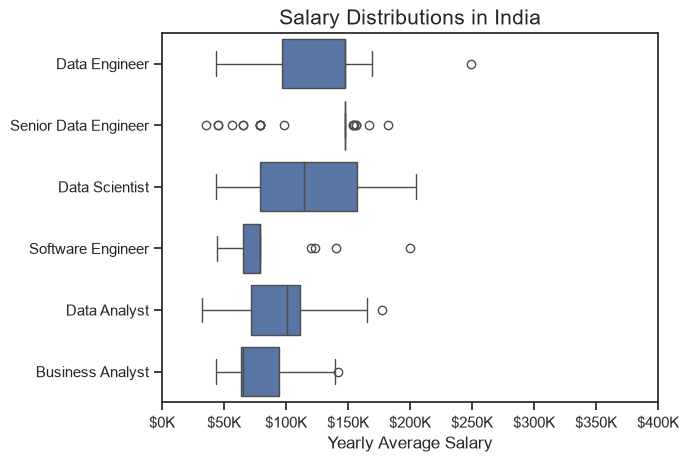

In [22]:
sns.boxplot(data=df_india_top, x='salary_year_avg', y='job_title_short')
sns.set_theme(style='ticks')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
plt.xlim(0, 400000)
plt.ylabel('')
plt.xlabel('Yearly Average Salary')
plt.title('Salary Distributions in India', fontsize=15)
plt.show()

In [23]:
df_india_anal = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()
df_exploded = df_india_anal.explode('job_skills').copy()
df_exploded.dropna(subset='salary_year_avg', inplace=True)

df_grp_exp = df_exploded.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

df_demand = df_grp_exp.nlargest(10, 'skill_count').reset_index()
df_money = df_grp_exp[df_grp_exp['skill_count'] > 10].nlargest(10, 'median_salary')

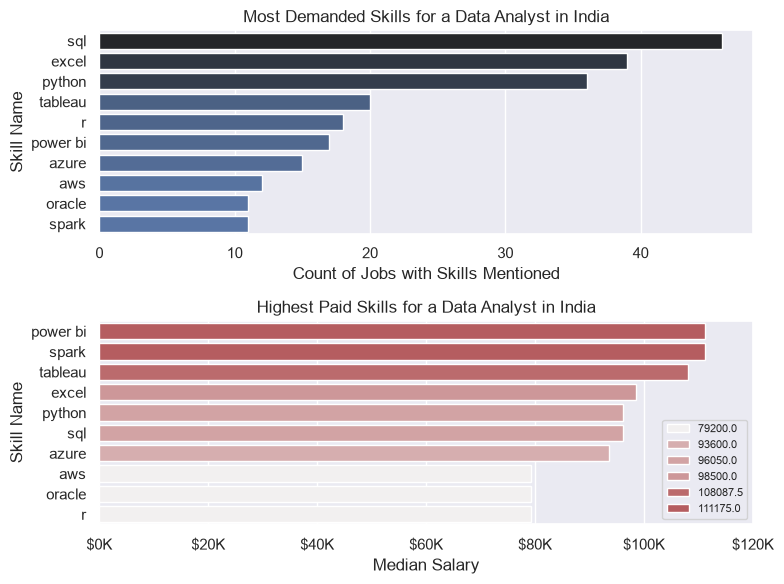

In [30]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.set_theme(style='darkgrid')
sns.barplot(data = df_demand, x = 'skill_count', y = 'job_skills', ax=ax[0], hue='skill_count', palette = 'dark:b_r', legend=False)
#df_demand[::-1].plot(kind='barh', ax=ax[0])
ax[0].set_title('Most Demanded Skills for a Data Analyst in India')
ax[0].set_ylabel('Skill Name')
ax[0].set_xlabel('Count of Jobs with Skills Mentioned')

sns.barplot(data = df_money, x = 'median_salary', y = 'job_skills', ax=ax[1], hue='median_salary', palette = 'light:r')
#df_money[::-1].plot(kind='barh', ax=ax[1])
ax[1].set_title('Highest Paid Skills for a Data Analyst in India')
ax[1].set_xlim(0, 120000)
ax[1].set_ylabel('Skill Name')
ax[1].set_xlabel('Median Salary')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
sns.move_legend(
    ax[1],
    'lower right',
    title='',
    fontsize=8,       # Smaller text size
    title_fontsize=8, # Smaller title size
    markerscale=0.7   # Smaller color swatches
)

plt.tight_layout()